# DSCI 552 Homework 7
### Multi-Class and Multi-Label Classification with SVMs, K-Means and Hierarchical Clustering

Name: Chihwei Huang

USC ID: 9265220160

## 0. Setup

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import Parallel, delayed
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.metrics import (balanced_accuracy_score, calinski_harabasz_score, pairwise_distances,
                             recall_score, silhouette_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)

DATA_DIR = Path("../data/Anuran Calls (MFCCs)")
SEED = 552
LABELS = ["Family", "Genus", "Species"]

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### 1a. Loading the data and choosing the training set

In [2]:
frogs = pd.read_csv(DATA_DIR / "Frogs_MFCCs.csv")
FEATURES = [c for c in frogs.columns if c.startswith("MFCCs_")]
X_all = frogs[FEATURES].to_numpy()
Y_all = frogs[LABELS]

print(f"{len(frogs)} instances, {len(FEATURES)} MFCC features, {frogs['RecordID'].nunique()} recordings")
print("Missing values:", frogs.isna().sum().sum())
print(f"Feature values go from {X_all.min():.3f} to {X_all.max():.3f}")
column_sd = frogs[FEATURES].std()
print(f"Standard deviations of the columns go from {column_sd.min():.3f} for {column_sd.idxmin()} "
      f"to {column_sd.max():.3f} for {column_sd.idxmax()}")
print("Most genera or families that one species belongs to:",
      frogs.groupby("Species")[["Genus", "Family"]].nunique().max().max())
display(frogs.groupby(LABELS).size().rename("Instances").reset_index())

7195 instances, 22 MFCC features, 60 recordings
Missing values: 0
Feature values go from -0.952 to 1.000
Standard deviations of the columns go from 0.069 for MFCCs_ 1 to 0.264 for MFCCs_ 3
Most genera or families that one species belongs to: 1


,Family,Genus,Species,Instances
0,Bufonidae,Rhinella,Rhinellagranulosa,68
1,Dendrobatidae,Ameerega,Ameeregatrivittata,542
2,Hylidae,Dendropsophus,HylaMinuta,310
3,Hylidae,Hypsiboas,HypsiboasCinerascens,472
4,Hylidae,Hypsiboas,HypsiboasCordobae,1121
5,Hylidae,Osteocephalus,OsteocephalusOophagus,114
6,Hylidae,Scinax,ScinaxRuber,148
7,Leptodactylidae,Adenomera,AdenomeraAndre,672
8,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3478
9,Leptodactylidae,Leptodactylus,LeptodactylusFuscus,270


The data has 7195 syllables from 60 recordings, with 22 MFCC features and no missing values. Each species
belongs to exactly one genus and one family, so the three labels form a tree. The classes are very
unbalanced. AdenomeraHylaedactylus has 3478 instances, but Rhinellagranulosa has only 68.

I take 70% of the rows at random as the training set. The split is stratified by species, so each species
has the same share in both sets. Since each species belongs to one genus and one family, the shares of the
genera and the families also stay the same. Without stratification, a small species like Rhinellagranulosa
could end up with very few test rows.

The rows are syllables, and each recording gives many syllables of the same frog. A random split puts
syllables of the same recording in both sets. So the test scores in this homework are likely higher than
the scores we would get on new recordings.

In [3]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X_all, Y_all, train_size=0.7, random_state=SEED, stratify=Y_all["Species"]
)
Y_train = Y_train.reset_index(drop=True)
Y_test = Y_test.reset_index(drop=True)

print(f"Training set: {len(X_train)} rows, which is {len(X_train) / len(X_all):.1%} of the data")
print(f"Test set:     {len(X_test)} rows")

Training set: 5036 rows, which is 70.0% of the data
Test set:     2159 rows


### 1b. Binary relevance

Binary relevance trains one classifier for each label and ignores the other labels. Here there are three
labels: Family with 4 classes, Genus with 8 classes and Species with 10 classes. So I train three
multi-class classifiers on the same 22 features. The prediction for an instance is the triplet of the
three predicted classes.

#### 1b-i. Exact match, Hamming loss and Hamming score

Let $n$ be the number of test instances and $L = 3$ the number of labels. For instance $i$, $y_{ij}$ is the
true class of label $j$ and $\hat y_{ij}$ is the predicted class. $Y_i$ is the set of the three true labels
and $Z_i$ is the set of the three predicted labels.

* **Exact match ratio**, also called subset accuracy, is the fraction of instances whose three labels are
  all right:
  $$\text{EMR} = \frac{1}{n}\sum_{i=1}^{n} I(Y_i = Z_i).$$
  It is the strictest measure. If the family and the genus are right but the species is wrong, the
  instance counts as completely wrong.
* **Hamming distance** of one instance is the number of labels that are wrong:
  $d_H(Y_i, Z_i) = \sum_{j=1}^{L} I(y_{ij} \ne \hat y_{ij})$. Here it is 0, 1, 2 or 3.
* **Hamming loss** is the fraction of all single labels that are wrong:
  $$\text{HL} = \frac{1}{nL}\sum_{i=1}^{n} d_H(Y_i, Z_i).$$
  Lower is better. Sorower defines it with $k$ binary labels and counts the labels that are in only one of
  $Y_i$ and $Z_i$. Here each label is one multi-class output, so I count one error for each wrong output.
  Then $1 - \text{HL}$ is the average accuracy of the three label classifiers.
* **Hamming score** is what Sorower calls accuracy, and it comes from Godbole and Sarawagi. It is the
  average Jaccard similarity of the true and the predicted label sets:
  $$\text{HS} = \frac{1}{n}\sum_{i=1}^{n} \frac{|Y_i \cap Z_i|}{|Y_i \cup Z_i|}.$$
  No class name is used by two labels. So if $c_i$ labels of instance $i$ are right, then
  $|Y_i \cap Z_i| = c_i$ and $|Y_i \cup Z_i| = 2L - c_i$. An instance gets 1 if all three labels are right,
  2/4 = 0.5 if two are right, 1/5 = 0.2 if one is right and 0 if none is right. This value is never more
  than $c_i / 3$ and never less than the exact match of the instance, so
  $\text{EMR} \le \text{HS} \le 1 - \text{HL}$.

The function below computes all four measures from a table of true labels and a table of predicted labels.
I use it for every model in 1b and for the clusters in Problem 2. In the small example, the first instance
is fully right, the second has the wrong species and the third has the wrong genus and species.

In [4]:
def multilabel_scores(Y_true, Y_pred):
    """Exact match, Hamming score, Hamming loss and average Hamming distance for multi-class labels."""
    Y_true, Y_pred = np.asarray(Y_true), np.asarray(Y_pred)
    n_labels = Y_true.shape[1]
    distance = (Y_true != Y_pred).sum(axis=1)        # Hamming distance of each instance
    correct = n_labels - distance                     # size of the intersection of Y and Z
    return pd.Series({
        "Exact match": np.mean(distance == 0),
        "Hamming score": np.mean(correct / (2 * n_labels - correct)),
        "Hamming loss": distance.mean() / n_labels,
        "Avg. Hamming distance": distance.mean(),
    })


all_names = [name for label in LABELS for name in frogs[label].unique()]
print("Class names shared by two labels:", len(all_names) - len(set(all_names)))

example_true = pd.DataFrame([["Hylidae", "Hypsiboas", "HypsiboasCordobae"]] * 3, columns=LABELS)
example_pred = pd.DataFrame([["Hylidae", "Hypsiboas", "HypsiboasCordobae"],
                             ["Hylidae", "Hypsiboas", "HypsiboasCinerascens"],
                             ["Hylidae", "Scinax", "ScinaxRuber"]], columns=LABELS)
print(multilabel_scores(example_true, example_pred).round(4).to_string())

Class names shared by two labels: 0
Exact match              0.3333
Hamming score            0.5667
Hamming loss             0.3333
Avg. Hamming distance    1.0000


The example gives an exact match of 1/3 and a Hamming loss of 3/9 = 1/3. The Hamming score is the mean of
1, 0.5 and 0.2, which is 0.5667. These are the values we expect.

#### 1b-ii. SVMs with a Gaussian kernel, one versus all

For a label with $K$ classes, one versus all trains $K$ binary SVMs. SVM $k$ separates class $k$ from all
the other classes. An instance gets the class whose SVM gives the largest decision value. `SVC` in
scikit-learn uses one versus one inside, so I wrap it in `OneVsRestClassifier`. The Gaussian kernel is

$$K(x, x') = \exp\left(-\frac{\lVert x - x' \rVert^2}{2\sigma^2}\right),$$

so the `gamma` of scikit-learn is $\gamma = \frac{1}{2\sigma^2}$. $C$ is the weight of the penalty on the
slack variables. A large $C$ means weak regularization.

The features are already scaled. Each row was divided by its largest absolute value, so every value is
between -1 and 1. But the columns still have very different spreads, as the output of 1a shows. So I fit
the models on both the raw features and the standardized features, where each column has mean 0 and
variance 1. The scaler is a step of the pipeline, so in cross-validation it only sees the training folds.

To choose the parameter ranges, I follow footnote 1. I train the SVM on the whole training set with very
small and very large values of $C$ and $\sigma$ and look at the training accuracy. I use Species because it
is the hardest label. It has 10 classes, and its largest class has only 48% of the data. Standardizing
makes the distances between points much larger, so the $\sigma$ values for the standardized features are
larger. The code prints the median distance between two training points for both cases.

Median distance between two training points, raw features: 0.94


Median distance between two training points, standardized features: 6.13


Scan took 92 seconds


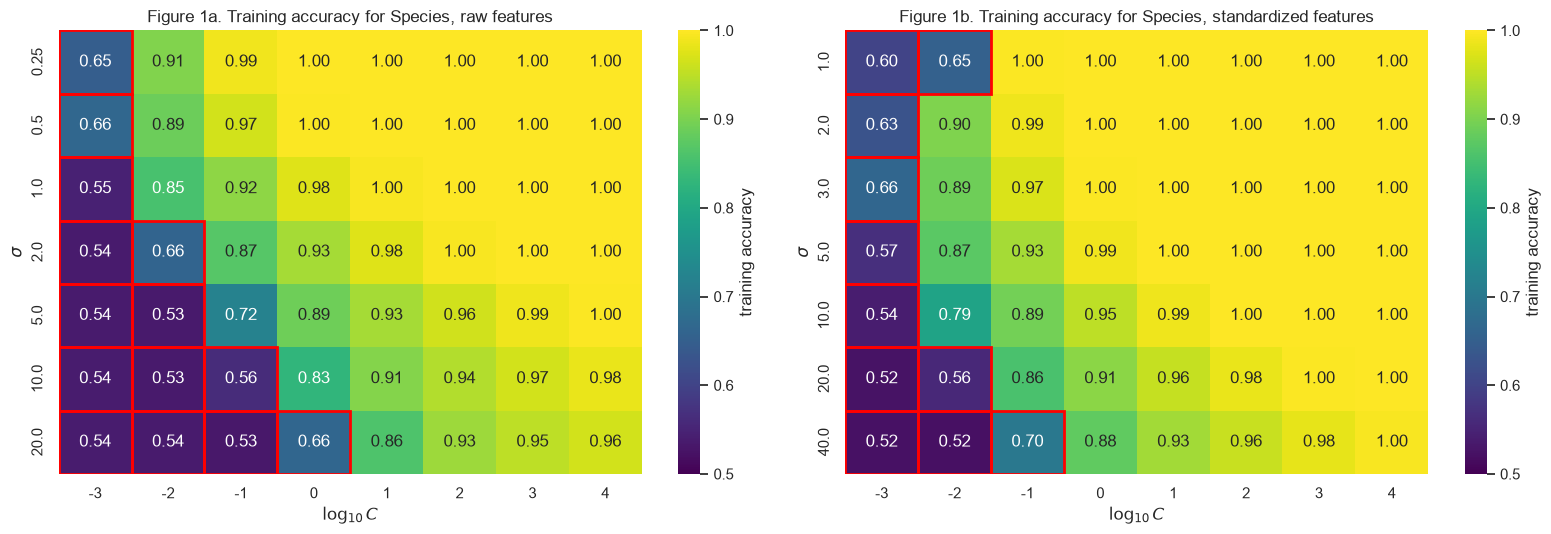

In [5]:
VERSION = {False: "raw", True: "standardized"}
X_train_std = StandardScaler().fit_transform(X_train)
for standardize, X in [(False, X_train), (True, X_train_std)]:
    print(f"Median distance between two training points, {VERSION[standardize]} features: {np.median(pdist(X)):.2f}")


def rbf_svm(C=1.0, sigma=1.0, standardize=False):
    svm = OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=1 / (2 * sigma**2), cache_size=500))
    return Pipeline([("scale", StandardScaler() if standardize else "passthrough"), ("svm", svm)])


def training_accuracy(C, sigma, standardize, label="Species"):
    model = rbf_svm(C, sigma, standardize).fit(X_train, Y_train[label])
    return {"standardize": standardize, "C": C, "sigma": sigma, "accuracy": model.score(X_train, Y_train[label])}


SCAN_C = 10.0 ** np.arange(-3, 5)
SCAN_SIGMA = {False: [0.25, 0.5, 1, 2, 5, 10, 20], True: [1, 2, 3, 5, 10, 20, 40]}

start = time.time()
scan = pd.DataFrame(Parallel(n_jobs=-1)(
    delayed(training_accuracy)(C, sigma, standardize)
    for standardize in [False, True] for C in SCAN_C for sigma in SCAN_SIGMA[standardize]
))
print(f"Scan took {time.time() - start:.0f} seconds")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, standardize in zip(axes, [False, True]):
    table = (scan[scan["standardize"] == standardize]
             .assign(log10_C=lambda d: np.log10(d["C"]).astype(int))
             .pivot(index="sigma", columns="log10_C", values="accuracy"))
    sns.heatmap(table, annot=True, fmt=".2f", cmap="viridis", vmin=0.5, vmax=1, ax=ax,
                cbar_kws={"label": "training accuracy"})
    for (r, c), value in np.ndenumerate(table.to_numpy()):
        if value < 0.7:
            ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor="red", lw=2))
    ax.set(xlabel=r"$\log_{10} C$", ylabel=r"$\sigma$",
           title=f"Figure 1{'b' if standardize else 'a'}. Training accuracy for Species, {VERSION[standardize]} features")
plt.tight_layout()
plt.show()

Figure 1 shows the training accuracy for Species. The red boxes mark the pairs where it is below 70%, and
all of them have $C \le 1$. With $C = 10^{-3}$ the accuracy is below 70% for every $\sigma$. With a larger
$C$ it is below 70% only when $\sigma$ is large, except for the standardized features with $C = 10^{-2}$
and $\sigma = 1$. A very small $C$ or a very wide kernel makes the SVM too simple, so it mostly predicts
the large classes. For $C \ge 10$ the training accuracy is at least 0.86 for every $\sigma$ in the plot,
and for a small $\sigma$ it reaches 1.00, so the SVM can fit the whole training set.

From this, I use $C = 1, 10, 10^2, 10^3, 10^4$ for cross-validation. The values $C = 10^{-2}$ and
$10^{-1}$ are above 70% for some $\sigma$, but for the same $\sigma$ their training accuracy is never
higher than at $C = 1$ and is usually lower, so they tend to underfit. I leave them out to keep the search
short. For $\sigma$ I use linear steps, as
footnote 1 suggests: $0.2, 0.4, \dots, 2.0$ for the raw features and $1, 2, \dots, 10$ for the
standardized features. Both ranges include the median distance between two training points, and they
cover the region where the training accuracy is high. Each grid has 50 pairs. With 10 folds, 3 labels and
2 versions of the features, this gives the 3000 fits below.

In [6]:
CV10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
RBF_C = 10.0 ** np.arange(0, 5)
RBF_SIGMA = {False: np.round(np.arange(0.2, 2.01, 0.2), 1), True: np.arange(1.0, 11.0)}


def tune(model, grid, label):
    """10-fold cross-validation on the training set. The best model is refit on the whole training set."""
    return GridSearchCV(model, grid, cv=CV10, scoring="accuracy", n_jobs=-1).fit(X_train, Y_train[label])


start = time.time()
rbf_searches = {}
for standardize in [False, True]:
    grid = {"svm__estimator__C": RBF_C, "svm__estimator__gamma": 1 / (2 * RBF_SIGMA[standardize] ** 2)}
    for label in LABELS:
        rbf_searches[standardize, label] = tune(rbf_svm(standardize=standardize), grid, label)
n_fits = sum(len(s.cv_results_["params"]) for s in rbf_searches.values()) * CV10.get_n_splits()
print(f"{n_fits} model fits took {(time.time() - start) / 60:.1f} minutes")

3000 model fits took 5.8 minutes


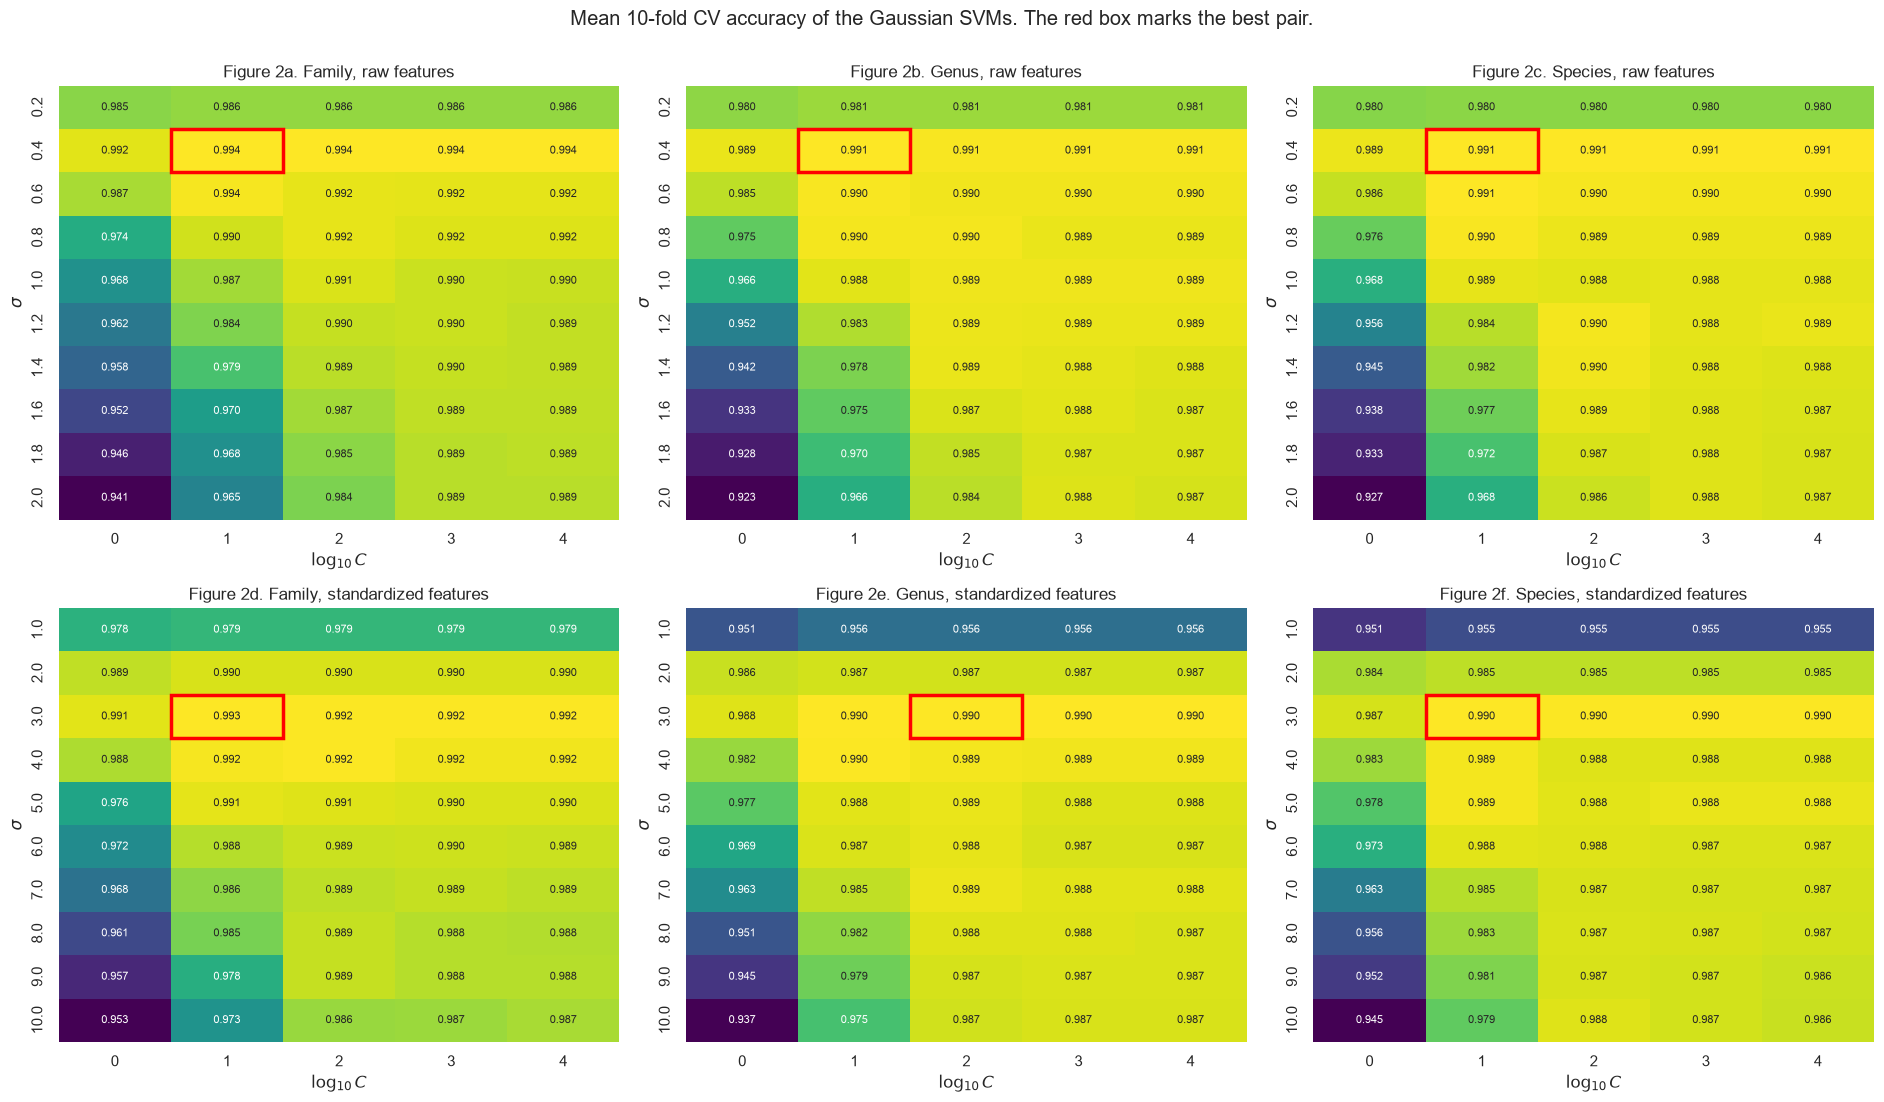

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
for row, standardize in enumerate([False, True]):
    for col, label in enumerate(LABELS):
        search = rbf_searches[standardize, label]
        res = pd.DataFrame(search.cv_results_)
        res["sigma"] = np.sqrt(1 / (2 * res["param_svm__estimator__gamma"].astype(float))).round(1)
        res["log10_C"] = np.log10(res["param_svm__estimator__C"].astype(float)).round().astype(int)
        table = res.pivot(index="sigma", columns="log10_C", values="mean_test_score")
        ax = axes[row, col]
        sns.heatmap(table, annot=True, fmt=".3f", cmap="viridis", cbar=False, ax=ax, annot_kws={"size": 8})
        best = np.unravel_index(np.argmax(table.to_numpy()), table.shape)
        ax.add_patch(plt.Rectangle(best[::-1], 1, 1, fill=False, edgecolor="red", lw=2.5))
        ax.set(xlabel=r"$\log_{10} C$", ylabel=r"$\sigma$",
               title=f"Figure 2{'abcdef'[3 * row + col]}. {label}, {VERSION[standardize]} features")
fig.suptitle("Mean 10-fold CV accuracy of the Gaussian SVMs. The red box marks the best pair.", y=1.0)
plt.tight_layout()
plt.show()

For each label, I use the pair of $C$ and $\sigma$ with the highest mean CV accuracy and refit the model on
the whole training set. The tables give the results for each label and the multi-label scores on the test
set.

In [8]:
def readable_params(params):
    out = {}
    for key, value in params.items():
        name = key.split("__")[-1]
        if name == "gamma":
            out["sigma"] = np.sqrt(1 / (2 * value))
        else:
            out[name] = value
    return out


def evaluate(searches):
    """Results for each label and multi-label test scores for a binary relevance model {label: search}."""
    rows, pred = [], {}
    for label in LABELS:
        search = searches[label]
        pred[label] = search.predict(X_test)
        row = {"Label": label, **readable_params(search.best_params_), "CV accuracy": search.best_score_,
               "Test accuracy": np.mean(pred[label] == Y_test[label]),
               "Test balanced accuracy": balanced_accuracy_score(Y_test[label], pred[label])}
        svm = search.best_estimator_.named_steps["svm"]
        if hasattr(svm, "coef_"):
            row["Avg. nonzero weights"] = (svm.coef_ != 0).sum(axis=1).mean()
        rows.append(row)
    Y_pred = pd.DataFrame(pred)[LABELS]
    return pd.DataFrame(rows).set_index("Label"), multilabel_scores(Y_test, Y_pred), Y_pred


label_tables, test_scores, test_predictions = {}, {}, {}
for standardize in [False, True]:
    name = f"Gaussian SVM, {VERSION[standardize]}"
    label_tables[name], test_scores[name], test_predictions[name] = evaluate(
        {label: rbf_searches[standardize, label] for label in LABELS})
    print(name)
    display(label_tables[name])

display(pd.DataFrame(test_scores).T)

Gaussian SVM, raw


,C,sigma,CV accuracy,Test accuracy,Test balanced accuracy
Label,,,,,
Family,10.0,0.4,0.9944,0.9944,0.9606
Genus,10.0,0.4,0.9913,0.9917,0.9545
Species,10.0,0.4,0.9911,0.9912,0.9608


Gaussian SVM, standardized


,C,sigma,CV accuracy,Test accuracy,Test balanced accuracy
Label,,,,,
Family,10.0,3.0,0.9927,0.9912,0.9575
Genus,100.0,3.0,0.9905,0.9893,0.9508
Species,10.0,3.0,0.9899,0.9903,0.9620


,Exact match,Hamming score,Hamming loss,Avg. Hamming distance
"Gaussian SVM, raw",0.9903,0.9917,0.0076,0.0227
"Gaussian SVM, standardized",0.9870,0.9893,0.0097,0.0292


In every panel of Figure 2 the best pair is inside the grid, not on its edge. The CV accuracy is lower at
the smallest $\sigma$ and slowly goes down for larger $\sigma$, so the grid covers the best region.

With the raw features, all three labels choose $\sigma = 0.4$ and $C = 10$. At $\sigma = 0.4$, all values of
$C$ from 10 to $10^4$ give about the same CV accuracy, so the exact value of $C$ matters little once it is
at least 10. With the standardized features, all three labels choose $\sigma = 3$, with $C = 10$ for
Family and Species and $C = 100$ for Genus. In both cases the best $\sigma$ is about half of the median
distance between two training points: 0.4 against 0.94, and 3 against 6.13. So the two versions choose
kernels of about the same relative width.

Both versions are very accurate. All CV and test accuracies are 0.989 or higher. The raw features are a
little better for every label, both in CV and on the test set. On the test set, the raw version has an
exact match of 0.9903 and a Hamming loss of 0.0076, and the standardized version has 0.9870 and 0.0097.
In counts, the raw version gets 21 of the 2159 test instances wrong and makes 49 label errors. The
standardized version gets 28 instances wrong and makes 63 label errors. So a wrong instance has more than
two wrong labels on average, which means the three classifiers tend to fail on the same instances.

A possible reason why standardizing does not help is that it gives every column the same weight. This
includes `MFCCs_ 1`, which is almost always 1 and has the smallest spread. With the raw features, the
columns that vary more have more effect on the distance.

The balanced accuracy is about 0.95 to 0.96 for both versions, a little lower than the accuracy. The last
table of 1b-iv shows that the two smallest species, OsteocephalusOophagus and Rhinellagranulosa, have the
lowest recall, about 0.85.

#### 1b-iii. $L_1$-penalized SVMs

Footnote 3 says to use the $L_1$ penalty with a linear kernel. For each class $k$, `LinearSVC` solves

$$\min_{w_k, b_k} \; \lVert w_k \rVert_1 + C \sum_{i=1}^{n} \max\big(0,\, 1 - t_{ik}(w_k^T x_i + b_k)\big)^2,$$

where $t_{ik} = 1$ if instance $i$ is in class $k$ and $t_{ik} = -1$ if it is not. This is the squared
hinge loss, which `LinearSVC` needs for the $L_1$ penalty. For more than two classes `LinearSVC` is one
versus all, as in 1b-ii. It uses liblinear, which treats the intercept $b_k$ as one more weight, so the
intercept is penalized too. The $L_1$ penalty can set weights to exactly zero, so a binary SVM may use only
some of the 22 features. The features are standardized inside the pipeline, so all weights are penalized on
the same scale.

To choose the range of $C$, I use the idea of footnote 1 again. I train the model on the whole training set
with $C$ from $10^{-4}$ to $10^{2}$ and look at the training accuracy and at the average number of nonzero
weights of the binary SVMs.

In [9]:
def l1_svm(smote=False):
    svm = LinearSVC(penalty="l1", loss="squared_hinge", dual=False, max_iter=20000, random_state=SEED)
    if smote:
        return ImbPipeline([("scale", StandardScaler()), ("smote", SMOTE(random_state=SEED)), ("svm", svm)])
    return Pipeline([("scale", StandardScaler()), ("svm", svm)])


def l1_training_fit(C, label):
    model = l1_svm().set_params(svm__C=C).fit(X_train, Y_train[label])
    return {"Label": label, "C": C, "Training accuracy": model.score(X_train, Y_train[label]),
            "Avg. nonzero weights": (model.named_steps["svm"].coef_ != 0).sum(axis=1).mean()}


l1_scan = pd.DataFrame(Parallel(n_jobs=-1)(
    delayed(l1_training_fit)(C, label) for label in LABELS for C in 10.0 ** np.arange(-4, 3)))
for value in ["Training accuracy", "Avg. nonzero weights"]:
    print(value)
    display(l1_scan.pivot(index="Label", columns="C", values=value))

Training accuracy


C,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000,100.0000
Label,,,,,,,
Family,0.0095,0.8628,0.9301,0.9380,0.9394,0.9396,0.9396
Genus,0.5766,0.8261,0.9162,0.9432,0.9559,0.9563,0.9565
Species,0.0933,0.7957,0.9172,0.9561,0.9629,0.9635,0.9635


Avg. nonzero weights


C,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000,100.0000
Label,,,,,,,
Family,0.0,6.000,13.500,18.75,21.5,21.500,22.0
Genus,0.0,2.875,10.625,18.25,21.5,21.875,22.0
Species,0.0,3.400,11.400,18.10,21.4,21.800,22.0


At $C = 10^{-4}$ the penalty sets every weight to zero. Liblinear also penalizes the intercept, so the
intercepts are zero too. Then every binary SVM gives the same score, and the model predicts the first class
in alphabetical order for every instance. So the training accuracy is just the share of that class: 0.0095
for Bufonidae, 0.5766 for Adenomera and 0.0933 for AdenomeraAndre. This is far below 70%. At $C = 10^{-3}$
the training accuracy is between 0.796 and 0.863, and the binary SVMs use only about 3 to 6 of the 22
features. As $C$ grows, more weights become nonzero and the accuracy goes up. From $C = 1$ on, the
training accuracy changes by less than 0.001, and almost all 22 weights are nonzero.

So I search $C$ from $10^{-3}$ to $10$ with 9 values that are evenly spaced in $\log C$:
$10^{-3}, 10^{-2.5}, \dots, 10^{1}$.

In [10]:
L1_GRID = {"svm__C": np.logspace(-3, 1, 9)}

start = time.time()
l1_searches = {label: tune(l1_svm(), L1_GRID, label) for label in LABELS}
print(f"Cross-validation took {time.time() - start:.0f} seconds")

name = "L1 linear SVM"
label_tables[name], test_scores[name], test_predictions[name] = evaluate(l1_searches)
display(label_tables[name])
display(test_scores[name].to_frame(name).T)

Cross-validation took 62 seconds


,C,CV accuracy,Test accuracy,Test balanced accuracy,Avg. nonzero weights
Label,,,,,
Family,1.0,0.9382,0.9333,0.6906,21.500
Genus,10.0,0.9523,0.9546,0.8416,21.875
Species,1.0,0.9575,0.9592,0.8824,21.400


,Exact match,Hamming score,Hamming loss,Avg. Hamming distance
L1 linear SVM,0.9166,0.94,0.0509,0.1528


The solid lines in Figure 3 show the CV accuracy of this model against $C$. CV chooses $C = 1$ for Family
and Species and $C = 10$ for Genus. $C = 10$ is the largest value in the grid, but the Genus curve is flat
from about $C = 0.3$ on, and the training accuracy above $C = 1$ hardly changes. So a larger $C$ would not
help. At these values of $C$ the penalty is weak, and the binary SVMs keep 21.4 to 21.9 of the 22 weights
on average. So almost every MFCC carries some useful information, and the $L_1$ penalty removes very few
of them.

The linear models are clearly worse than the Gaussian SVMs. On the test set, the exact match is 0.9166 and
the Hamming loss is 0.0509, while the Gaussian SVM on raw features has 0.9903 and 0.0076. The classes are
not linearly separable in the 22 features, and the Gaussian kernel can draw curved boundaries. The balanced
accuracies are low, 0.69 for Family, 0.84 for Genus and 0.88 for Species, while the accuracies are 0.93
to 0.96. So the linear SVMs miss many instances of the small classes.

#### 1b-iv. $L_1$-penalized SVMs with SMOTE

The classes are very unbalanced. Leptodactylidae has 65 times as many instances as Bufonidae, and
AdenomeraHylaedactylus has 51 times as many instances as Rhinellagranulosa. SMOTE by Chawla et al. makes
new instances for the small classes. It picks an instance of a small class and one of its 5 nearest
neighbors from the same class. Then it puts a new point at a random place on the line between them. By
default, every class is oversampled to the size of the largest class. I put SMOTE in an `imblearn` pipeline
between the scaler and the SVM. So SMOTE only runs when the model is fit, and only on the training folds.
The validation folds and the test set keep their real class sizes. I choose $C$ in the same way as in
1b-iii.

The first table shows the number of training instances of each species before and after SMOTE.

In [11]:
_, y_smote = SMOTE(random_state=SEED).fit_resample(X_train_std, Y_train["Species"])
display(pd.DataFrame({"Before SMOTE": Y_train["Species"].value_counts(),
                      "After SMOTE": y_smote.value_counts()}).T)

start = time.time()
smote_searches = {label: tune(l1_svm(smote=True), L1_GRID, label) for label in LABELS}
print(f"Cross-validation took {time.time() - start:.0f} seconds")

name = "L1 linear SVM + SMOTE"
label_tables[name], test_scores[name], test_predictions[name] = evaluate(smote_searches)
display(label_tables[name])
display(test_scores[name].to_frame(name).T)

Species,AdenomeraAndre,AdenomeraHylaedactylus,Ameeregatrivittata,HylaMinuta,HypsiboasCinerascens,HypsiboasCordobae,LeptodactylusFuscus,OsteocephalusOophagus,Rhinellagranulosa,ScinaxRuber
Before SMOTE,470,2434,379,217,330,785,189,80,48,104
After SMOTE,2434,2434,2434,2434,2434,2434,2434,2434,2434,2434


Cross-validation took 1044 seconds


,C,CV accuracy,Test accuracy,Test balanced accuracy,Avg. nonzero weights
Label,,,,,
Family,0.3162,0.9295,0.9194,0.8942,21.75
Genus,10.0000,0.9251,0.9097,0.8966,22.00
Species,0.1000,0.9549,0.9620,0.9205,21.30


,Exact match,Hamming score,Hamming loss,Avg. Hamming distance
L1 linear SVM + SMOTE,0.8657,0.9126,0.0696,0.2089


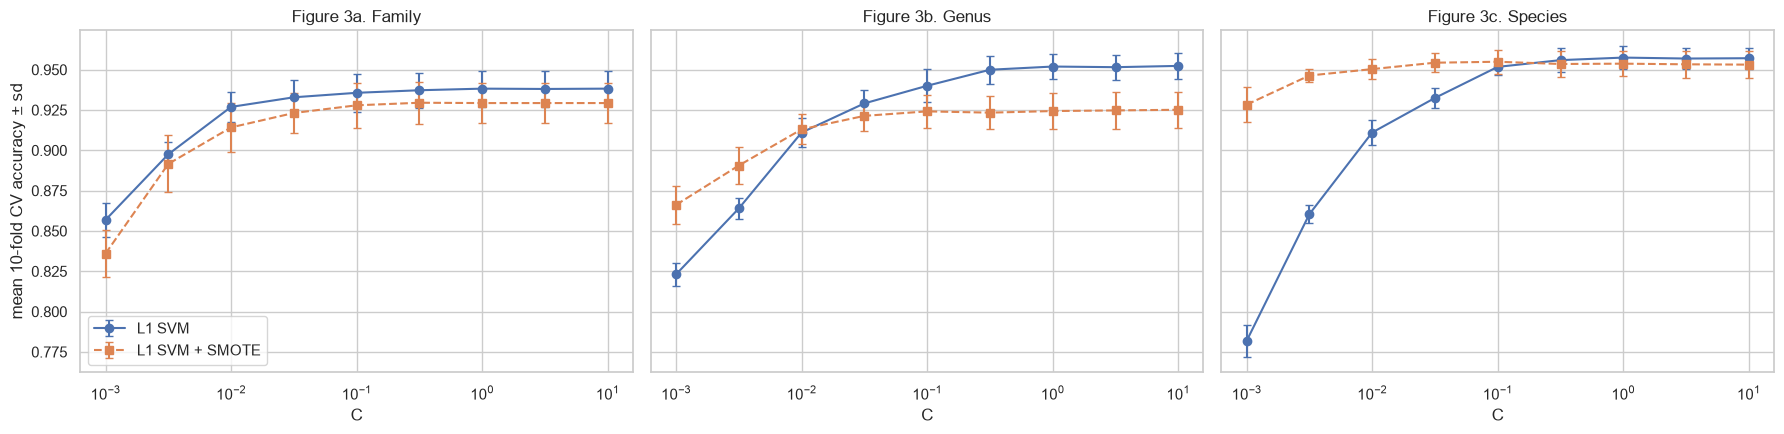

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, label in zip(axes, LABELS):
    for searches, style, name in [(l1_searches, "o-", "L1 SVM"), (smote_searches, "s--", "L1 SVM + SMOTE")]:
        res = searches[label].cv_results_
        ax.errorbar(res["param_svm__C"].astype(float), res["mean_test_score"], yerr=res["std_test_score"],
                    fmt=style, capsize=3, label=name)
    ax.set(xscale="log", xlabel="C", title=f"Figure 3{'abc'[LABELS.index(label)]}. {label}")
axes[0].set_ylabel("mean 10-fold CV accuracy ± sd")
axes[0].legend()
plt.tight_layout()
plt.show()

#### Comparison of all classifiers on the test set

The first table has the multi-label scores. The second table has the balanced accuracy of each label.
Balanced accuracy is the mean of the recalls of the classes, so every class counts the same. The third
table has the recall of each species.

In [13]:
comparison = pd.DataFrame(test_scores).T
display(comparison)

display(pd.DataFrame({name: table["Test balanced accuracy"] for name, table in label_tables.items()}).T)

species_order = Y_train["Species"].value_counts().index
recall = pd.DataFrame({
    name: pd.Series(recall_score(Y_test["Species"], pred["Species"], labels=species_order, average=None),
                    index=species_order)
    for name, pred in test_predictions.items()
})
recall.insert(0, "Test instances", Y_test["Species"].value_counts()[species_order])
display(recall)

,Exact match,Hamming score,Hamming loss,Avg. Hamming distance
"Gaussian SVM, raw",0.9903,0.9917,0.0076,0.0227
"Gaussian SVM, standardized",0.9870,0.9893,0.0097,0.0292
L1 linear SVM,0.9166,0.9400,0.0509,0.1528
L1 linear SVM + SMOTE,0.8657,0.9126,0.0696,0.2089


Label,Family,Genus,Species
"Gaussian SVM, raw",0.9606,0.9545,0.9608
"Gaussian SVM, standardized",0.9575,0.9508,0.9620
L1 linear SVM,0.6906,0.8416,0.8824
L1 linear SVM + SMOTE,0.8942,0.8966,0.9205


,Test instances,"Gaussian SVM, raw","Gaussian SVM, standardized",L1 linear SVM,L1 linear SVM + SMOTE
Species,,,,,
AdenomeraHylaedactylus,1044,0.9990,0.9981,0.9981,0.9943
HypsiboasCordobae,336,1.0000,1.0000,0.9673,0.9464
AdenomeraAndre,202,0.9851,0.9752,0.9455,0.9208
Ameeregatrivittata,163,1.0000,1.0000,0.9387,0.9264
HypsiboasCinerascens,142,0.9789,0.9789,0.9577,0.9577
HylaMinuta,93,0.9892,0.9892,0.7527,0.9140
LeptodactylusFuscus,81,0.9753,0.9753,0.9506,0.9383
ScinaxRuber,44,0.9773,1.0000,0.9545,0.9545
OsteocephalusOophagus,34,0.8529,0.8529,0.5588,0.8529


With SMOTE, CV chooses $C = 0.316$ for Family, $C = 10$ for Genus and $C = 0.1$ for Species. The dashed
lines in Figure 3 show that the best CV accuracy with SMOTE is lower for Family and Genus and about the
same for Species. The CV accuracy is measured on validation folds with the real class sizes.

My conclusions about the classifiers:

1. The Gaussian SVMs are the best classifiers by far. With the raw features they have an exact match of
   0.9903, a Hamming score of 0.9917 and a Hamming loss of 0.0076. Their balanced accuracies are also the
   highest, about 0.95 to 0.96, so they do well on the small classes even without SMOTE. The raw features
   are a little better than the standardized features.
2. The $L_1$-penalized linear SVMs are much worse, with an exact match of 0.9166 and a Hamming loss of
   0.0509. A linear boundary is not flexible enough for this data, and the penalty that CV chooses removes
   almost no features.
3. SMOTE helps the small classes. The balanced accuracy goes up for every label: from 0.69 to 0.89 for
   Family, from 0.84 to 0.90 for Genus and from 0.88 to 0.92 for Species. The recall of HylaMinuta goes
   from 0.75 to 0.91, and the recall of OsteocephalusOophagus goes from 0.56 to 0.85.
4. SMOTE also moves the boundaries toward the large classes, so the model makes more mistakes on some
   large classes. For example, the recall of HypsiboasCordobae drops from 0.97 to 0.95. For Species the two
   effects almost cancel, and the accuracy even rises a little, from 0.959 to 0.962. But the Family
   accuracy falls from 0.933 to 0.919, and the Genus accuracy falls from 0.955 to 0.910. Exact match and
   Hamming loss count every test instance the same, and most test instances are in large classes. So both
   get worse with SMOTE: the exact match falls from 0.9166 to 0.8657, and the Hamming loss rises from
   0.0509 to 0.0696.
5. So SMOTE is useful when the small classes matter as much as the large ones, but not when the goal is
   the best exact match or Hamming loss. Here CV chose $C$ by accuracy, which favors the large classes.
   Choosing $C$ by balanced accuracy would fit better with the goal of SMOTE.
6. In every model, an instance with an error has between 1.6 and 2.3 wrong labels out of 3 on average.
   This is the average Hamming distance divided by one minus the exact match. So the errors of the three
   classifiers happen on the same instances. The labels are strongly related, but binary relevance ignores
   this.
7. The scores are likely too optimistic for new recordings, because syllables of the same recording are in
   both the training set and the test set.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

One run of the Monte-Carlo simulation does 2a, 2b and 2c once, and I do 50 runs. Run $r$ uses
`random_state = r` for k-means, so the runs differ only in the random starting centers. Each k-means fit
keeps the best of 10 starts. I use all 7195 instances and the 22 features as they are, without the labels.

### 2a. Choosing k with the silhouette

For instance $i$, let $a(i)$ be its average distance to the other members of its cluster, and let $b(i)$
be its average distance to the members of the nearest other cluster. The silhouette of instance $i$ is

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}.$$

The average of $s(i)$ over all instances is high when the clusters are tight and far apart. In each run I
fit k-means for every $k$ from 2 to 50 and keep the $k$ with the largest average silhouette. $k = 1$ cannot
be scored, because $b(i)$ does not exist when there is only one cluster. The CH index cannot score $k = 1$
either.
I also compute the CH index in every run to compare the two methods.

The silhouette needs all $7195^2$ distances. Computing them again for each of the $50 \times 49$
clusterings is slow. So I compute the distance matrix once and get the silhouette from it with one matrix
product. The first cell checks the result against `silhouette_score` from scikit-learn.

In [14]:
D_all = pairwise_distances(X_all).astype(np.float32)   # all Euclidean distances, computed once


def silhouette(D, clusters):
    """Average silhouette width from a full distance matrix."""
    rows = np.arange(len(clusters))
    sizes = np.bincount(clusters)
    sums = D @ np.eye(len(sizes), dtype=D.dtype)[clusters]       # distance sums to each cluster
    a = sums[rows, clusters] / np.maximum(sizes[clusters] - 1, 1)
    mean_dist = sums / sizes
    mean_dist[rows, clusters] = np.inf
    b = mean_dist.min(axis=1)
    return np.mean(np.where(sizes[clusters] > 1, (b - a) / np.maximum(a, b), 0.0))


check = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_all).labels_
print(f"Silhouette for k = 4, fast version: {silhouette(D_all, check):.6f}")
print(f"Silhouette for k = 4, scikit-learn: {silhouette_score(X_all, check):.6f}")

Silhouette for k = 4, fast version: 0.378751


Silhouette for k = 4, scikit-learn: 0.378751


50 runs took 5.3 minutes
Number of runs that chose each k


Chosen k,2,4
Silhouette,0,50
CH index,50,0


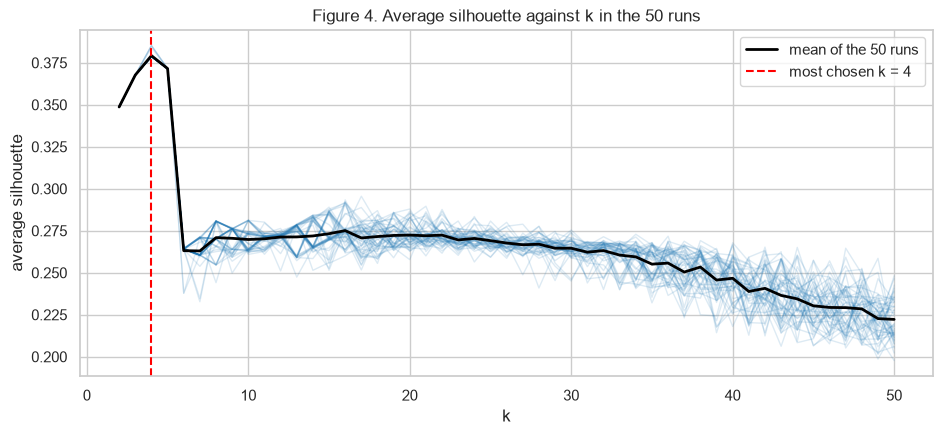

In [15]:
K_VALUES = np.arange(2, 51)
N_RUNS = 50


def majority_triplets(clusters, Y):
    """Majority family, genus and species of each cluster."""
    return Y.groupby(clusters)[LABELS].agg(lambda s: s.value_counts().idxmax())


def monte_carlo_run(run, X, D, Y):
    sil, ch, fits = [], [], {}
    for k in K_VALUES:
        fits[k] = KMeans(n_clusters=k, n_init=10, random_state=run).fit(X).labels_
        sil.append(silhouette(D, fits[k]))
        ch.append(calinski_harabasz_score(X, fits[k]))
    best_k = int(K_VALUES[np.argmax(sil)])
    clusters = fits[best_k]
    majority = majority_triplets(clusters, Y)                     # 2b
    Y_pred = majority.loc[clusters].reset_index(drop=True)        # each instance gets its cluster's triplet
    return {"run": run, "k": best_k, "k_ch": int(K_VALUES[np.argmax(ch)]), "silhouette": np.array(sil),
            "clusters": clusters, "majority": majority, **multilabel_scores(Y, Y_pred)}  # 2c


start = time.time()
mc = Parallel(n_jobs=-1)(delayed(monte_carlo_run)(run, X_all, D_all, Y_all) for run in range(N_RUNS))
print(f"{N_RUNS} runs took {(time.time() - start) / 60:.1f} minutes")

chosen_k = pd.DataFrame({"Silhouette": pd.Series([r["k"] for r in mc]).value_counts(),
                         "CH index": pd.Series([r["k_ch"] for r in mc]).value_counts()}).fillna(0).astype(int)
chosen_k.index.name = "Chosen k"
print("Number of runs that chose each k")
display(chosen_k.T)

k_mode = pd.Series([r["k"] for r in mc]).mode()[0]
sil = np.array([r["silhouette"] for r in mc])
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(K_VALUES, sil.T, color="tab:blue", alpha=0.15, lw=1)
ax.plot(K_VALUES, sil.mean(axis=0), color="black", lw=2, label="mean of the 50 runs")
ax.axvline(k_mode, color="red", ls="--", label=f"most chosen k = {k_mode}")
ax.set(xlabel="k", ylabel="average silhouette", title="Figure 4. Average silhouette against k in the 50 runs")
ax.legend()
plt.show()

The silhouette chose $k = 4$ in all 50 runs. Figure 4 shows why. The average silhouette is about 0.35 at
$k = 2$, rises to a peak of about 0.38 at $k = 4$, is still about 0.37 at $k = 5$ and then drops to about
0.27 at $k = 6$. For larger $k$ it slowly goes down to about 0.22 at $k = 50$. The 50 curves are close to
each other, especially for small $k$.

The CH index chose $k = 2$ in all 50 runs, which is fewer clusters than the 4 families. I use the
silhouette, so $k = 4$ in every run. Four clusters match the number of families, but 2b shows that the
clusters do not match the families exactly.

### 2b. Majority labels of each cluster

For each cluster, I take the most common family, the most common genus and the most common species of its
members. Each of the three is found on its own. The table shows run 0. The share columns give the fraction
of the cluster that has the majority class.

In [16]:
run0 = mc[0]
table = run0["majority"].copy()
table.insert(0, "Size", np.bincount(run0["clusters"]))
for pos, label in zip([2, 4, 6], LABELS):
    share = Y_all[label].groupby(run0["clusters"]).agg(lambda s: s.value_counts(normalize=True).iloc[0])
    table.insert(pos, f"{label} share", share)
table.index.name = "Cluster"
print(f"Run 0: k = {run0['k']}")
display(table)

triplet_sets = {tuple(sorted(map(tuple, r["majority"].to_numpy()))) for r in mc}
print(f"Different sets of majority triplets in the {N_RUNS} runs: {len(triplet_sets)}")

Run 0: k = 4


,Size,Family,Family share,Genus,Genus share,Species,Species share
Cluster,,,,,,,
0,3568,Leptodactylidae,0.9717,Adenomera,0.9714,AdenomeraHylaedactylus,0.9714
1,1982,Hylidae,0.6282,Hypsiboas,0.5237,HypsiboasCordobae,0.5136
2,1031,Dendrobatidae,0.4850,Ameerega,0.4850,Ameeregatrivittata,0.4850
3,614,Hylidae,0.9609,Hypsiboas,0.8827,HypsiboasCinerascens,0.7362


Different sets of majority triplets in the 50 runs: 3


In run 0 the four clusters are very different. Cluster 0 has 3568 instances, and 97% of them are
AdenomeraHylaedactylus, so it is almost pure. Cluster 3 is mostly Hylidae and Hypsiboas, but only 74% of it
is HypsiboasCinerascens. Clusters 1 and 2 are mixed. In cluster 2 the majority classes Dendrobatidae,
Ameerega and Ameeregatrivittata have only 48.5% of the members.

Each label is chosen on its own, so a triplet could mix a species with a genus or a family that it does
not belong to. This does not happen here. All four triplets are real combinations from the table in 1a.
Only 4 of the 10 species, 3 of the 8 genera and 3 of the 4 families appear as majority labels. So every
instance of the other 6 species gets a wrong species label. Across the 50 runs there are 3 different sets
of majority triplets, because some runs end in a different local optimum of k-means.

### 2c. Hamming distance, Hamming score and Hamming loss

Every instance gets the majority triplet of its cluster as its predicted labels. I compare these with the
true labels using the measures from 1b-i: the average Hamming distance, which is the number of wrong labels
out of 3, the Hamming score and the Hamming loss. I also list the exact match ratio. The second table gives
the mean and the standard deviation over the 50 runs.

In [17]:
mc_scores = pd.DataFrame([{key: r[key] for key in ["run", "k", "Avg. Hamming distance", "Hamming score",
                                                  "Hamming loss", "Exact match"]} for r in mc]).set_index("run")
display(mc_scores.head())

summary = mc_scores.drop(columns="k").agg(["mean", "std"]).T
summary.columns = ["Mean over 50 runs", "Standard deviation"]
display(summary)

,k,Avg. Hamming distance,Hamming score,Hamming loss,Exact match
run,,,,,
0,4,0.6673,0.7703,0.2224,0.7555
1,4,0.6673,0.7703,0.2224,0.7555
2,4,0.7354,0.7324,0.2451,0.6830
3,4,0.6673,0.7703,0.2224,0.7555
4,4,0.6673,0.7703,0.2224,0.7555


,Mean over 50 runs,Standard deviation
Avg. Hamming distance,0.6719,0.0170
Hamming score,0.7677,0.0094
Hamming loss,0.2240,0.0057
Exact match,0.7507,0.0178


Over the 50 runs, the mean of the average Hamming distance is 0.6719 with a standard deviation of 0.0170.
The Hamming score is 0.7677 with a standard deviation of 0.0094, and the Hamming loss is 0.2240 with a
standard deviation of 0.0057. So an instance gets about 0.67 of its 3 labels wrong on average, and 22.4%
of all labels are wrong. The exact match is 0.7507, so about three out of four instances get all three
labels right. Most of these come from cluster 0. In run 0, cluster 0 holds 3466 of the 3478
AdenomeraHylaedactylus instances, and all of them get three right labels. The values also follow
$\text{EMR} \le \text{HS} \le 1 - \text{HL}$ from 1b-i: $0.7507 \le 0.7677 \le 0.7760$.

The standard deviations are small. Every run chose $k = 4$, and the first five runs show that different
random starts often end in the same clustering, with an average Hamming distance of 0.6673. Only some runs,
like run 2, end in a worse clustering, with 0.7354.

K-means does not use the labels, so it is much worse than the SVMs in Problem 1. Its Hamming loss is 0.224,
while the best SVM has 0.0076. With only 4 clusters, at most 4 of the 10 species can ever be predicted.

## 3. ISLR 12.6.2

The dissimilarity matrix of the four observations is

$$
\begin{bmatrix}
 & 0.3 & 0.4 & 0.7 \\
0.3 & & 0.5 & 0.8 \\
0.4 & 0.5 & & 0.45 \\
0.7 & 0.8 & 0.45 &
\end{bmatrix}.
$$

With complete linkage, the dissimilarity between two clusters is the largest dissimilarity between their
members.

1. The smallest dissimilarity is $d(1, 2) = 0.3$, so 1 and 2 fuse at height 0.3.
2. $d(\{1,2\}, 3) = \max\{0.4, 0.5\} = 0.5$, $d(\{1,2\}, 4) = \max\{0.7, 0.8\} = 0.8$ and $d(3, 4) = 0.45$.
   The smallest is 0.45, so 3 and 4 fuse at height 0.45.
3. $d(\{1,2\}, \{3,4\}) = \max\{0.4, 0.5, 0.7, 0.8\} = 0.8$, so the two clusters fuse at height 0.8.

With single linkage, the dissimilarity between two clusters is the smallest dissimilarity between their
members.

1. 1 and 2 fuse at height 0.3, as before.
2. $d(\{1,2\}, 3) = \min\{0.4, 0.5\} = 0.4$, $d(\{1,2\}, 4) = \min\{0.7, 0.8\} = 0.7$ and $d(3, 4) = 0.45$.
   The smallest is 0.4, so 3 joins 1 and 2 at height 0.4.
3. $d(\{1,2,3\}, 4) = \min\{0.7, 0.8, 0.45\} = 0.45$, so 4 joins the others at height 0.45.

The code checks these steps with `scipy` and draws the dendrograms in Figure 5. In each dendrogram, the
dotted lines and the numbers on the vertical axis show the height of each fusion.

Fusion heights, complete linkage: [0.3, 0.45, 0.8]
Fusion heights, single linkage:   [0.3, 0.4, 0.45]
Two clusters, complete linkage: [[1, 2], [3, 4]]
Two clusters, single linkage: [[1, 2, 3], [4]]


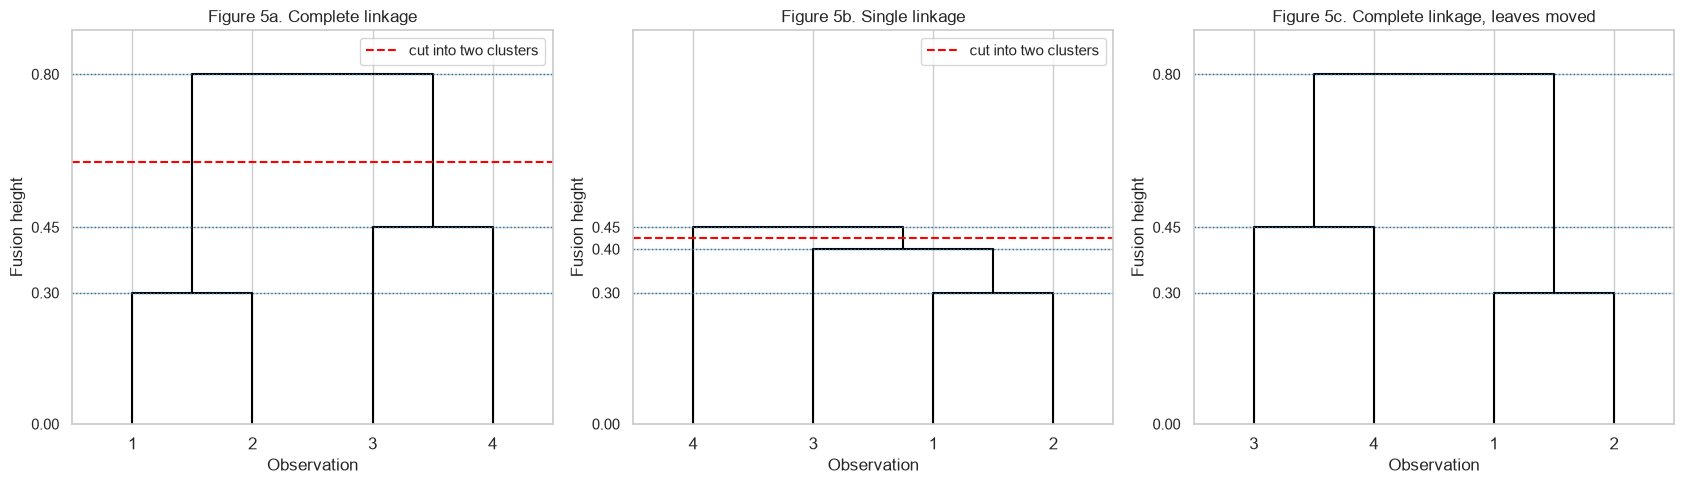

In [18]:
D_islr = np.array([[0.0, 0.3, 0.4, 0.7],
                   [0.3, 0.0, 0.5, 0.8],
                   [0.4, 0.5, 0.0, 0.45],
                   [0.7, 0.8, 0.45, 0.0]])
Z_complete = linkage(squareform(D_islr), method="complete")
Z_single = linkage(squareform(D_islr), method="single")
Z_swapped = Z_complete.copy()
Z_swapped[-1, [0, 1]] = Z_swapped[-1, [1, 0]]        # swap the two branches of the top fusion

print("Fusion heights, complete linkage:", Z_complete[:, 2].tolist())
print("Fusion heights, single linkage:  ", Z_single[:, 2].tolist())
for name, Z in [("complete", Z_complete), ("single", Z_single)]:
    groups = fcluster(Z, t=2, criterion="maxclust")
    print(f"Two clusters, {name} linkage:", [[int(i) + 1 for i in np.flatnonzero(groups == g)] for g in np.unique(groups)])


def draw(Z, ax, title, cut=None):
    dendrogram(Z, labels=["1", "2", "3", "4"], ax=ax, color_threshold=0, above_threshold_color="black")
    heights = Z[:, 2]
    for h in heights:                                 # dotted line and axis tick at each fusion height
        ax.axhline(h, color="tab:blue", ls=":", lw=1)
    ax.set_yticks(np.concatenate([[0.0], heights]))
    if cut is not None:
        ax.axhline(cut, color="red", ls="--", label="cut into two clusters")
        ax.legend(loc="upper right")
    ax.set(ylim=(0, 0.9), xlabel="Observation", ylabel="Fusion height", title=title)


fig, axes = plt.subplots(1, 3, figsize=(17, 5))
draw(Z_complete, axes[0], "Figure 5a. Complete linkage", cut=0.6)
draw(Z_single, axes[1], "Figure 5b. Single linkage", cut=0.425)
draw(Z_swapped, axes[2], "Figure 5c. Complete linkage, leaves moved")
plt.tight_layout()
plt.show()

**a.** Figure 5a is the complete linkage dendrogram. Observations 1 and 2 fuse at 0.3, observations 3 and 4
fuse at 0.45, and the two pairs fuse at 0.8.

**b.** Figure 5b is the single linkage dendrogram. Observations 1 and 2 fuse at 0.3, observation 3 joins
them at 0.4, and observation 4 joins last at 0.45.

**c.** If we cut the complete linkage dendrogram between 0.45 and 0.8, as the red line in Figure 5a does, we
get two clusters. One cluster has observations 1 and 2, and the other has observations 3 and 4.

**d.** If we cut the single linkage dendrogram between 0.4 and 0.45, as the red line in Figure 5b does, we
get two clusters. One cluster has observations 1, 2 and 3, and the other has only observation 4.

**e.** Figure 5c is the dendrogram of part a with the two branches of the top fusion swapped. The leaves are
now in the order 3, 4, 1, 2, so all four leaves have moved. The fusions are still the same: 1 with 2 at 0.3,
3 with 4 at 0.45, and the two pairs at 0.8. So this dendrogram means the same thing as the one in part a.